In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# Online vs Offline graphs

In [13]:
remap_test = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/Nudged_run_cph_03_03/resample_test/remap_laf_whole_ryan_nudged_test_v0203_ctp_2d_ml_20080902T000000Z.nc")
remap_working = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/Nudged_run_cph_03_03/remaped_ctp/remap_laf_whole_ryan_nudged_test_v0203_ctp_2d_ml_20080902T000000Z.nc")

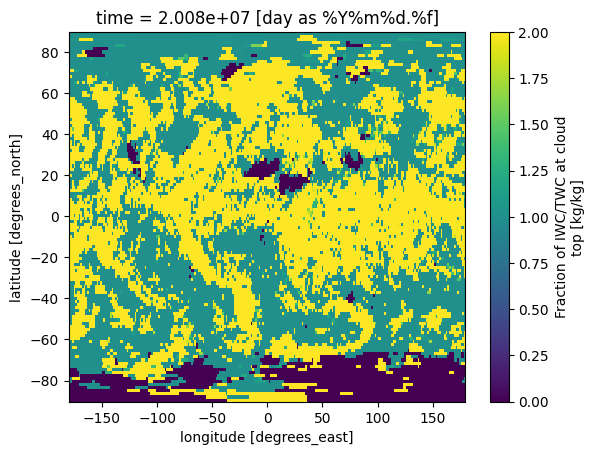

In [14]:
remap_working.ctp.isel(time=1).plot()

In [2]:
import re
import glob
import xarray as xr

pattern = "/wolke_scratch/dnikolo/dump/icon_3d_claas_grid/Offline_ct_laf_E-*_all_20080901000000.nc"

datasets = {}

for path in glob.glob(pattern):
    m = re.search(r"E-([0-9.]+)_all_20080901000000\.nc$", path)
    if m:
        number = float(m.group(1))   # or keep as string: m.group(1)
        datasets[number] = xr.open_dataset(path)

print(datasets.keys())

dict_keys([4.0, 5.0, 6.0])


In [3]:
claas_data=xr.open_dataset("/wolke_scratch/dnikolo/CLAAS_Data/sp/2008/09/01/CTXin20080901001500405SVMSG01MD.nc")

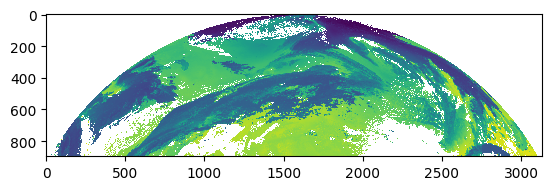

In [4]:
plt.imshow(np.flip(claas_data.ctt.values[0],axis=0),interpolation="None")

In [5]:
(np.flip(claas_data.ctt.values[0],axis=0)>0).mean()

0.5757478711641056

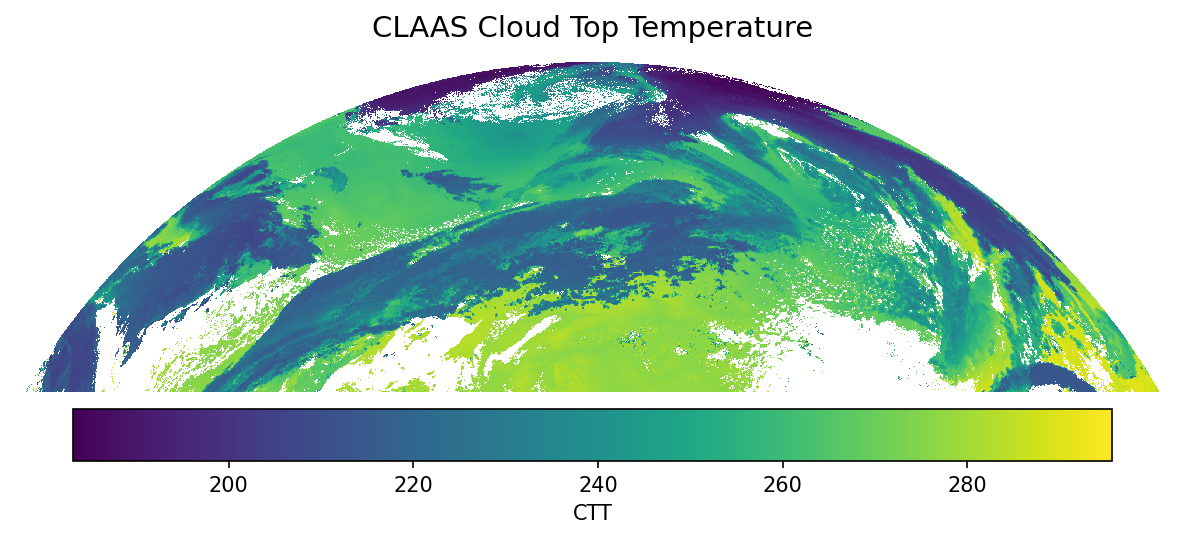

In [10]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6), dpi=150)

im = ax.imshow(
    np.flip(claas_data.ctt.values[0], axis=0),
    interpolation="none",
    cmap="viridis"
)

ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)

cbar = plt.colorbar(im, ax=ax, shrink=0.9, pad=0.02,orientation="horizontal")
cbar.set_label("CTT")

ax.set_title("CLAAS Cloud Top Temperature", fontsize=14, pad=12)

plt.tight_layout()
plt.show()

Cloud cover key E4.0 0.7207606754717962
Cloud cover key E5.0 0.9940617508741437
Cloud cover key E6.0 0.99923526631772


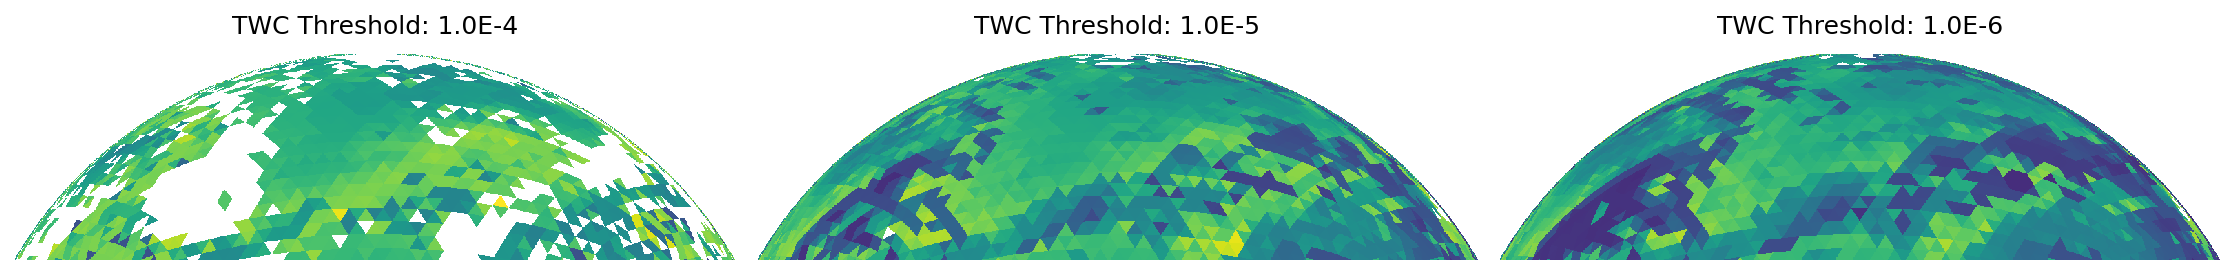

In [29]:
import math
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

# Sort datasets by key
items = sorted(datasets.items(), key=lambda kv: float(kv[0]))

n = len(items)
ncols = min(3, n)
nrows = math.ceil(n / ncols)

fig, axs = plt.subplots(
    nrows, ncols,
    figsize=(5 * ncols, 4.2 * nrows),
    dpi=150,
    squeeze=False
)

# Common color scale across all panels
vmin = min(np.nanmin(np.where(ds.ctt_filtered.isel(time=1).values > 1,
                              ds.ctt_filtered.isel(time=1).values,
                              np.nan))
           for _, ds in items)

vmax = max(np.nanmax(np.where(ds.ctt_filtered.isel(time=1).values > 1,
                              ds.ctt_filtered.isel(time=1).values,
                              np.nan))
           for _, ds in items)

im = None
for ax, (key, ds) in zip(axs.flat, items):
    data = ds.ctt_filtered.isel(time=1).values
    data = np.where(data > 1, data, np.nan)

    print(f"Cloud cover key E{key}", (data > 0).mean() / (1 - outside_globe_const))

    im = ax.imshow(
        data,
        origin="lower",
        interpolation="none",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(f"TWC Threshold: 1.0E-{int(key)}", fontsize=12, pad=10)
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

# Hide unused axes
for ax in axs.flat[n:]:
    ax.set_visible(False)

# fig.suptitle("ICON Cloud Top Temperature")
# Shared horizontal colorbar
# cbar = fig.colorbar(
#     im,
#     ax=axs,
#     orientation="horizontal",
#     shrink=0.9,
#     pad=0.06
# )
# cbar.set_label("CTT Filtered")

plt.tight_layout()
plt.show()

In [12]:
outside_globe_const = 1-(datasets[6.0].ctt_filtered.values>0).mean()

Cloud cover key E4.0 0.7207606754717962
Cloud cover key E5.0 0.9940617508741437
Cloud cover key E6.0 0.99923526631772


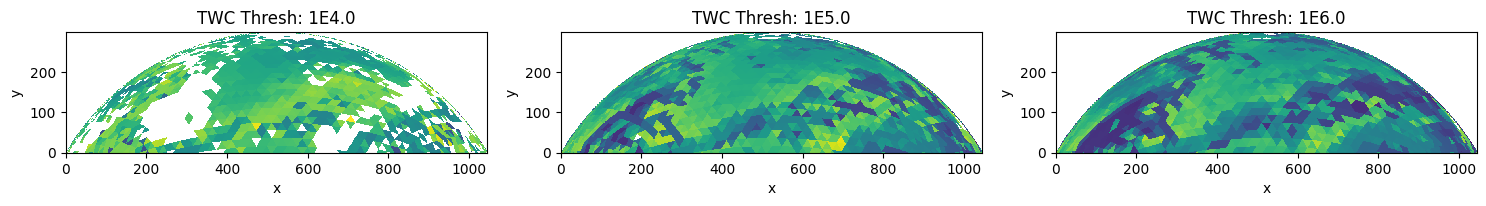

In [41]:
import math
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

# datasets = {...}   # your dictionary from before

# Sort by key if keys are numeric/string-numeric
items = sorted(datasets.items(), key=lambda kv: float(kv[0]))

n = len(items)
ncols = min(3, n)                  # up to 3 columns; adjust if you want
nrows = math.ceil(n / ncols)

fig, axs = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows), squeeze=False)

# Optional: compute common color scale across all panels
vmin = min(ds.ctt_filtered.isel(time=1).min().item() for _, ds in items)
vmax = max(ds.ctt_filtered.isel(time=1).max().item() for _, ds in items)

im = None
for ax, (key, ds) in zip(axs.flat, items):
    data = ds.ctt_filtered.isel(time=1).values

    # optional masking like in your online example
    data = np.where(data > 1, data, np.nan)
    print(f"Cloud cover key E{key}",(data>0).mean()/(1-outside_globe_const))
    im = ax.imshow(data, origin="lower", vmin=vmin, vmax=vmax,interpolation="None")
    ax.set_title(f"TWC Thresh: 1E{key}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

# Hide unused axes
for ax in axs.flat[n:]:
    ax.set_visible(False)

# One shared colorbar
# fig.colorbar(im, ax=axs, shrink=0.85, label="ctt_filtered", orientation="horizontal",pos="bottom")

plt.tight_layout()
plt.show()

In [16]:
remap_test.cph.isel(time=1).plot()

AttributeError: 'Dataset' object has no attribute 'cph'

In [17]:
remap_method = "laf"
online_ct = xr.open_dataset(f"/wolke_scratch/dnikolo/ICON_Data/Testing/online_ct_data/Online_ct_{remap_method}_all_20080902000000.nc")
offline_ct = xr.open_dataset(f"/wolke_scratch/dnikolo/ICON_Data/Testing/offline_ct_data_new/Offline_ct_{remap_method}_all_20080902000000.nc")

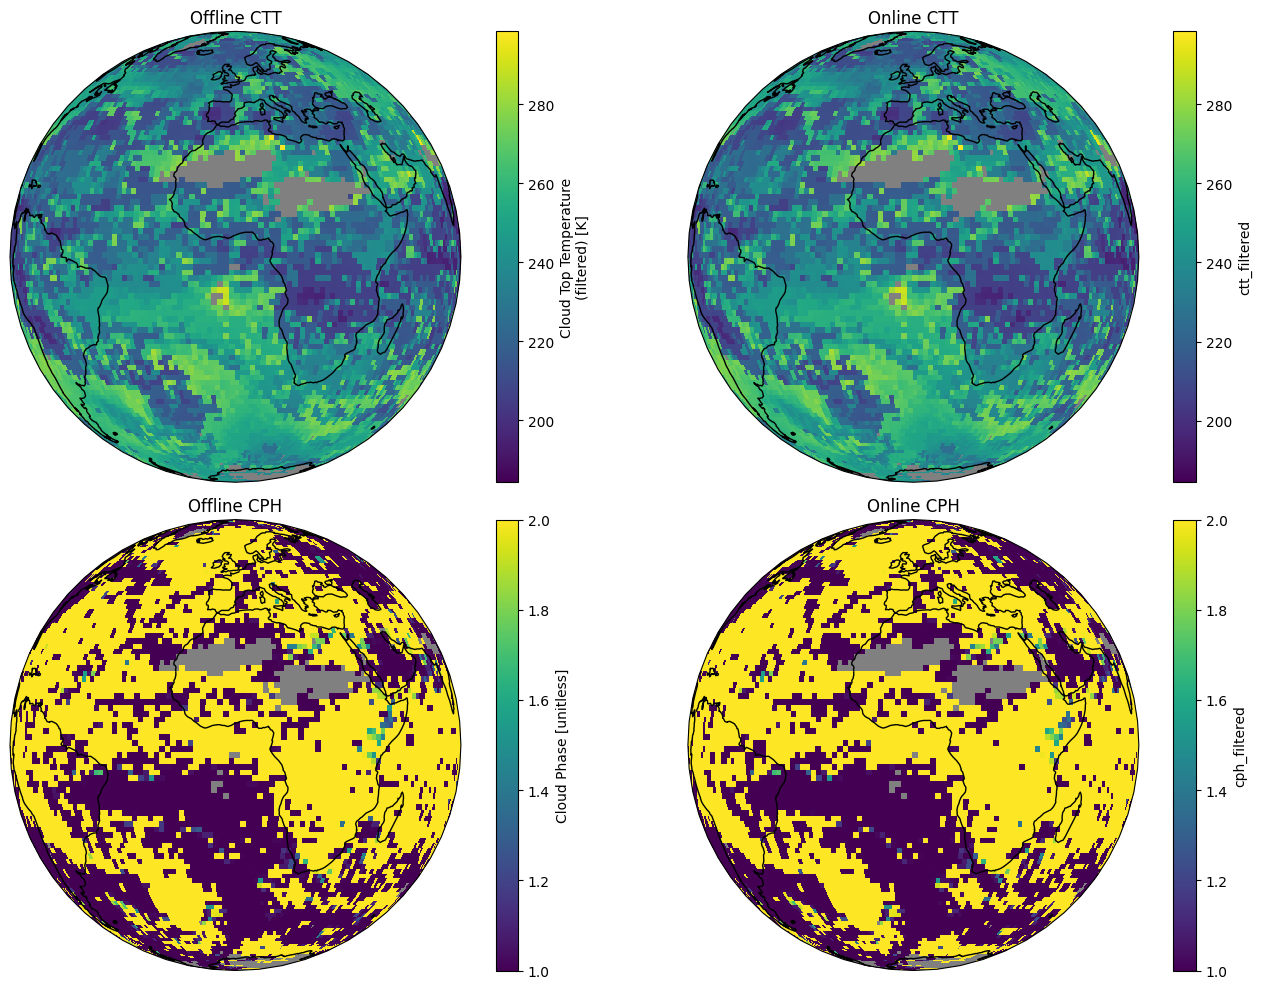

In [18]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# Common map projections
map_proj = ccrs.Orthographic(0, 0)
data_proj = ccrs.PlateCarree()

# Create 2x2 figure with cartopy axes
fig, axs = plt.subplots(
    2, 2,
    figsize=(14, 10),
    subplot_kw=dict(projection=map_proj, facecolor="gray")
)

# 1) Offline CTT
offline_ct.ctt_filtered.isel(time=1).plot(
    ax=axs[0, 0],
    transform=data_proj,
    add_colorbar=True
)
axs[0, 0].coastlines()
axs[0, 0].set_title("Offline CTT")

# 2) Online CTT
xr.where(
    online_ct.ctt_filtered > 1,
    online_ct.ctt_filtered,
    np.nan
).isel(time=1).plot(
    ax=axs[0, 1],
    transform=data_proj,
    add_colorbar=True
)
axs[0, 1].coastlines()
axs[0, 1].set_title("Online CTT")

# 3) Offline CPH
offline_ct.cph_filtered.isel(time=1).plot(
    ax=axs[1, 0],
    transform=data_proj,
    add_colorbar=True
)
axs[1, 0].coastlines()
axs[1, 0].set_title("Offline CPH")

# 4) Online CPH
xr.where(
    online_ct.cph_filtered >= 1-1e-5,
    online_ct.cph_filtered,
    np.nan
).isel(time=1).plot(
    ax=axs[1, 1],
    transform=data_proj,
    add_colorbar=True
)
axs[1, 1].coastlines()
axs[1, 1].set_title("Online CPH")

plt.tight_layout()
plt.show()

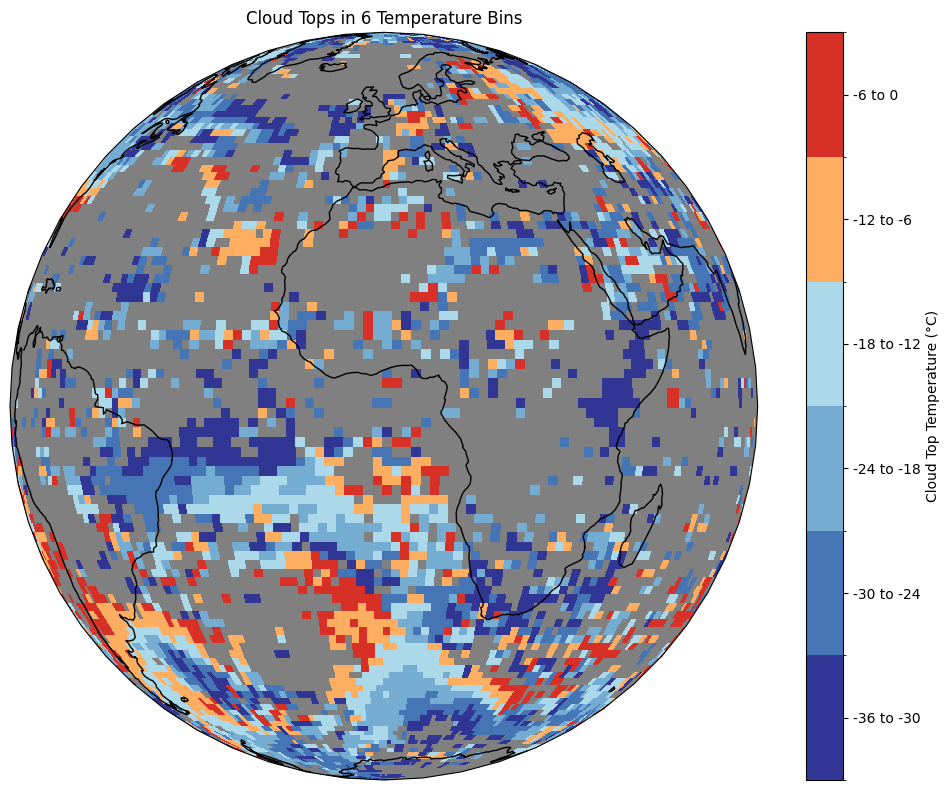

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs

# Projections
map_proj = ccrs.Orthographic(0, 0)
data_proj = ccrs.PlateCarree()

# Temperature bins
bins = [-36, -30, -24, -18, -12, -6, 0]

# One color per bin (6 bins => 6 colors)
colors = [
    "#313695",  # -36 to -30
    "#4575b4",  # -30 to -24
    "#74add1",  # -24 to -18
    "#abd9e9",  # -18 to -12
    "#fdae61",  # -12 to -6
    "#d73027",  # -6 to 0
]

cmap = mcolors.ListedColormap(colors)
norm = mcolors.BoundaryNorm(bins, cmap.N)

# Select your cloud-top temperature field
ctt = offline_ct.ctt_filtered.isel(time=1)-273.15  # Convert from K to °C

# Keep only values inside the requested range
ctt_binned = ctt.where((ctt >= -36) & (ctt <= 0))

# Plot
fig, ax = plt.subplots(
    figsize=(10, 8),
    subplot_kw=dict(projection=map_proj, facecolor="gray")
)

im = ctt_binned.plot(
    ax=ax,
    transform=data_proj,
    cmap=cmap,
    norm=norm,
    add_colorbar=True,
    cbar_kwargs={
        "ticks": [-33, -27, -21, -15, -9, -3],
        "label": "Cloud Top Temperature (°C)"
    }
)

# Custom colorbar labels for each bin
cbar = im.colorbar
cbar.ax.set_yticklabels([
    "-36 to -30",
    "-30 to -24",
    "-24 to -18",
    "-18 to -12",
    "-12 to -6",
    "-6 to 0"
])

ax.coastlines()
ax.set_title("Cloud Tops in 6 Temperature Bins")

plt.tight_layout()
plt.show()



In [20]:
remap_method = "dis"
online_ct = xr.open_dataset(f"/wolke_scratch/dnikolo/ICON_Data/Testing/online_ct_data/Online_ct_{remap_method}_all_20080902000000.nc")
offline_ct = xr.open_dataset(f"/wolke_scratch/dnikolo/ICON_Data/Testing/offline_ct_data_new/Offline_ct_{remap_method}_all_20080902000000.nc")

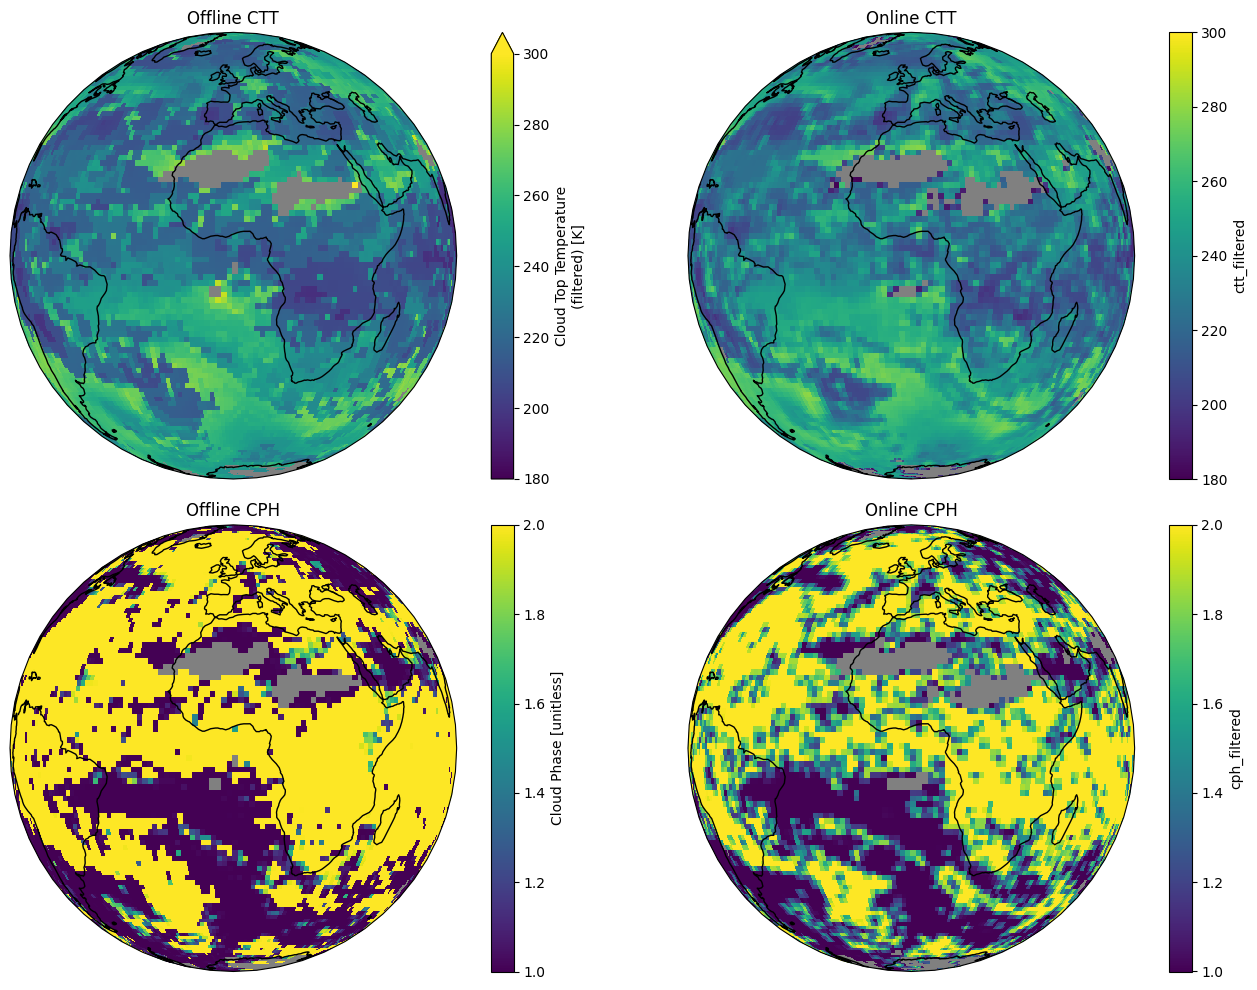

In [21]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# Common map projections
map_proj = ccrs.Orthographic(0, 0)
data_proj = ccrs.PlateCarree()

# Create 2x2 figure with cartopy axes
fig, axs = plt.subplots(
    2, 2,
    figsize=(14, 10),
    subplot_kw=dict(projection=map_proj, facecolor="gray")
)

# 1) Offline CTT
offline_ct.ctt_filtered.isel(time=1).plot(
    ax=axs[0, 0],
    transform=data_proj,
    vmin=180,
    vmax=300,
    add_colorbar=True
)
axs[0, 0].coastlines()
axs[0, 0].set_title("Offline CTT")

# 2) Online CTT
xr.where(
    (online_ct.ctt_filtered > 180),
    online_ct.ctt_filtered,
    np.nan
).isel(time=1).plot(
    ax=axs[0, 1],
    vmin=180,
    vmax=300,
    transform=data_proj,
    add_colorbar=True
)
axs[0, 1].coastlines()
axs[0, 1].set_title("Online CTT")

# 3) Offline CPH
offline_ct.cph_filtered.isel(time=1).plot(
    ax=axs[1, 0],
    transform=data_proj,
    add_colorbar=True
)
axs[1, 0].coastlines()
axs[1, 0].set_title("Offline CPH")

# 4) Online CPH
xr.where(
    online_ct.cph_filtered >= 1-1e-5,
    online_ct.cph_filtered,
    np.nan
).isel(time=1).plot(
    ax=axs[1, 1],
    transform=data_proj,
    add_colorbar=True
)
axs[1, 1].coastlines()
axs[1, 1].set_title("Online CPH")

plt.tight_layout()
plt.show()

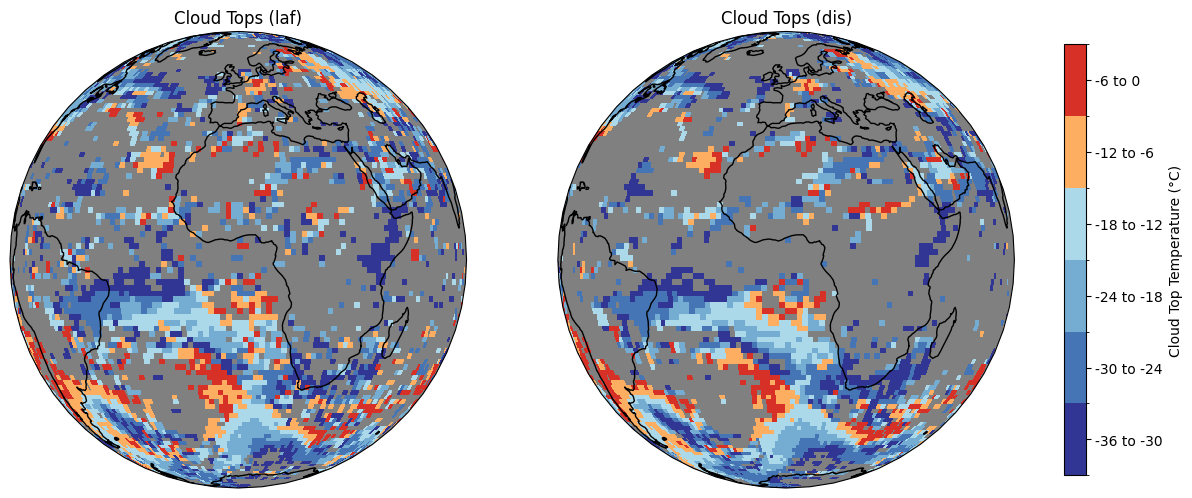

In [25]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs

# Projections
map_proj = ccrs.Orthographic(0, 0)
data_proj = ccrs.PlateCarree()

# Temperature bins
bins = [-36, -30, -24, -18, -12, -6, 0]

# One color per bin
colors = [
    "#313695",  # -36 to -30
    "#4575b4",  # -30 to -24
    "#74add1",  # -24 to -18
    "#abd9e9",  # -18 to -12
    "#fdae61",  # -12 to -6
    "#d73027",  # -6 to 0
]

cmap = mcolors.ListedColormap(colors)
norm = mcolors.BoundaryNorm(bins, cmap.N)

# Remap methods to compare
remap_methods = ["laf", "dis"]

# Create side-by-side figure
fig, axs = plt.subplots(
    1, 2,
    figsize=(16, 7),
    subplot_kw=dict(projection=map_proj, facecolor="gray")
)

# Loop through each remap method
for ax, remap_method in zip(axs, remap_methods):
    online_ct = xr.open_dataset(
        f"/wolke_scratch/dnikolo/ICON_Data/Testing/online_ct_data/Online_ct_{remap_method}_all_20080902000000.nc"
    )
    offline_ct = xr.open_dataset(
        f"/wolke_scratch/dnikolo/ICON_Data/Testing/offline_ct_data_new/Offline_ct_{remap_method}_all_20080902000000.nc"
    )

    # Select cloud-top temperature field (using offline, as in your first code)
    ctt = offline_ct.ctt_filtered.isel(time=1) -273.15

    # Keep only values in the desired range
    ctt_binned = ctt.where((ctt >= -36) & (ctt <= 0))

    # Plot without individual colorbars
    im = ctt_binned.plot(
        ax=ax,
        transform=data_proj,
        cmap=cmap,
        norm=norm,
        add_colorbar=False
    )

    ax.coastlines()
    ax.set_title(f"Cloud Tops ({remap_method})")

# Shared colorbar
cbar = fig.colorbar(
    im,
    ax=axs,
    orientation="vertical",
    shrink=0.8,
    pad=0.04,
    ticks=[-33, -27, -21, -15, -9, -3],
    label="Cloud Top Temperature (°C)"
)

cbar.ax.set_yticklabels([
    "-36 to -30",
    "-30 to -24",
    "-24 to -18",
    "-18 to -12",
    "-12 to -6",
    "-6 to 0"
])

# plt.tight_layout()
plt.show()

# Development

In [2]:
satellite_ct_cpp = xr.open_dataset("/wolke_scratch/dnikolo/CLAAS_Data/np/2007/09/01/CPPin20070901000000405SVMSG01MD.nc")
satellite_ct_ctx = xr.open_dataset("/wolke_scratch/dnikolo/CLAAS_Data/np/2007/09/01/CTXin20070901000000405SVMSG01MD.nc")

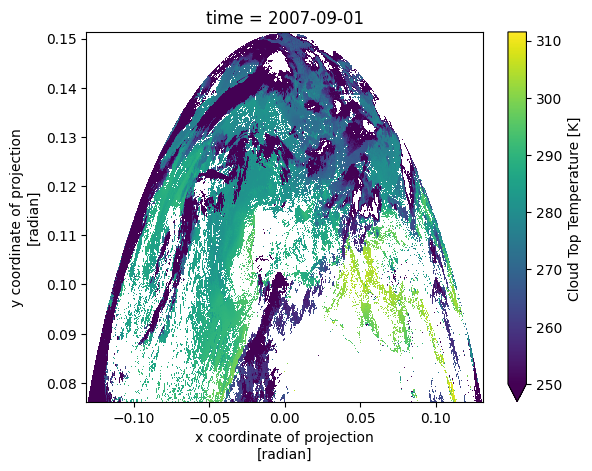

In [3]:
satellite_ct_ctx.ctt.isel(time=0).plot(vmin=250)

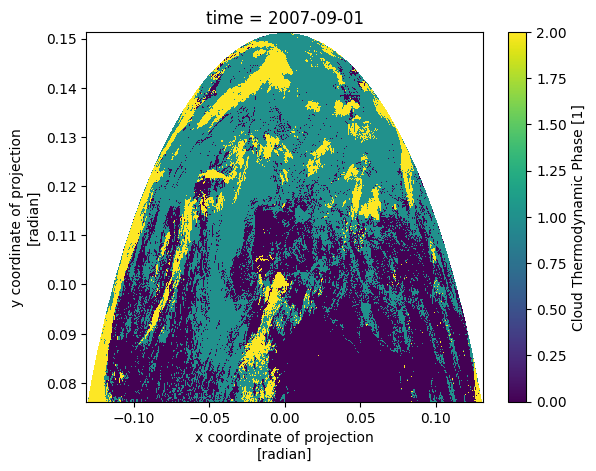

In [4]:
satellite_ct_cpp.cph.isel(time=0).plot()

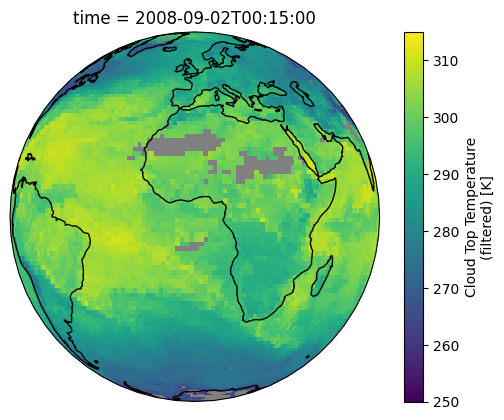

In [11]:
import cartopy.crs as ccrs


p = offline_ct.ctt_filtered.isel(time=1).plot( subplot_kws=dict(projection=ccrs.Orthographic(0, 0), facecolor="gray"), transform=ccrs.PlateCarree(), vmin=250)


p.axes.coastlines()

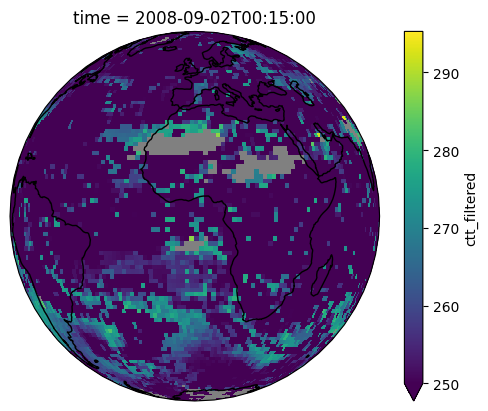

In [12]:

p = xr.where(online_ct.ctt_filtered>1, online_ct.ctt_filtered, np.nan).isel(time=1).plot( subplot_kws=dict(projection=ccrs.Orthographic(0, 0), facecolor="gray"), transform=ccrs.PlateCarree(), vmin=250)
p.axes.coastlines()

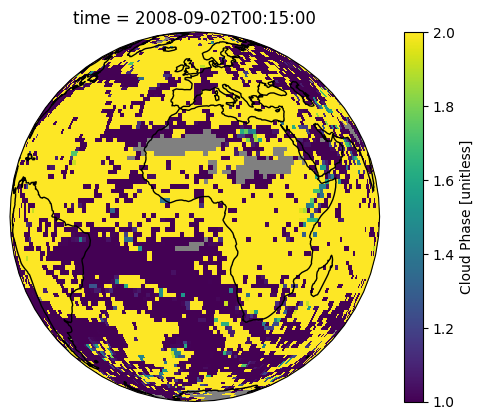

In [13]:
p = offline_ct.cph_filtered.isel(time=1).plot( subplot_kws=dict(projection=ccrs.Orthographic(0, 0), facecolor="gray"), transform=ccrs.PlateCarree())
p.axes.coastlines()

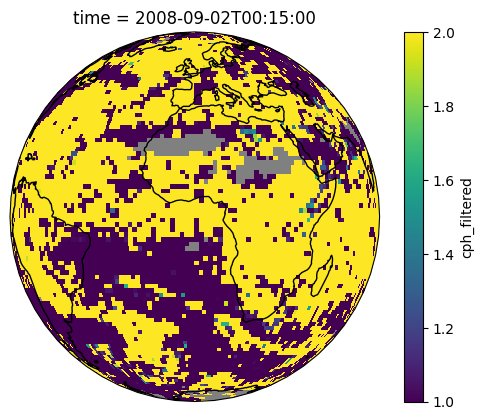

In [14]:
p = xr.where(online_ct.cph_filtered>0.99, online_ct.cph_filtered, np.nan).isel(time=1).plot( subplot_kws=dict(projection=ccrs.Orthographic(0, 0), facecolor="gray"), transform=ccrs.PlateCarree())
p.axes.coastlines()

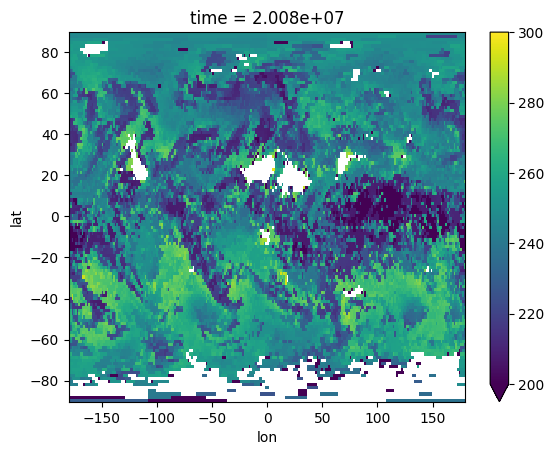

In [30]:
xr.where(online_ct.ctmask>0,  online_ct.ctt, np.nan).isel(time=0).plot(vmin=200, vmax=300)

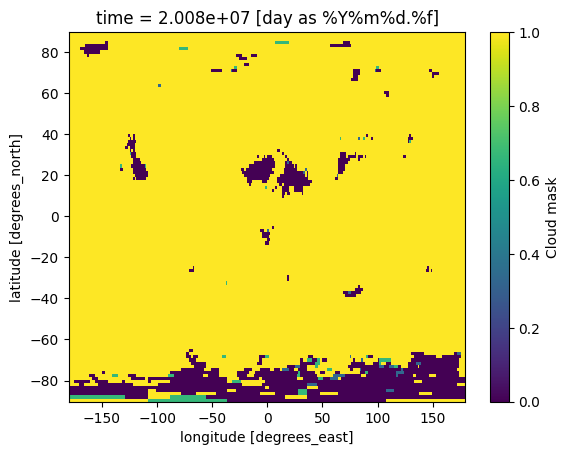

In [19]:
online_ct.ctmask.isel(time=0).plot()

In [4]:
offline_ct

<xarray.Dataset>
Dimensions:       (time: 96, lon: 240, lat: 67)
Coordinates:
  * time          (time) datetime64[ns] 2008-09-01 ... 2008-09-01T23:45:00
  * lon           (lon) float64 -179.5 -178.0 -176.5 ... 176.0 177.5 179.0
  * lat           (lat) float64 -79.0 -77.5 -76.0 -74.5 ... 75.5 77.0 78.5 80.0
Data variables:
    cph_filtered  (time, lat, lon) float64 ...
    ctt_filtered  (time, lat, lon) float64 ...

In [ ]:
offline_3d_data_sample = xr.open_dataset("/wolke_scratch/dnikolo/ICON_Data/CT_data_from_3d/Filtered_Data/np/2008/09/02/R_Agg_30_T_06_00_20080902010000.nc")
online_

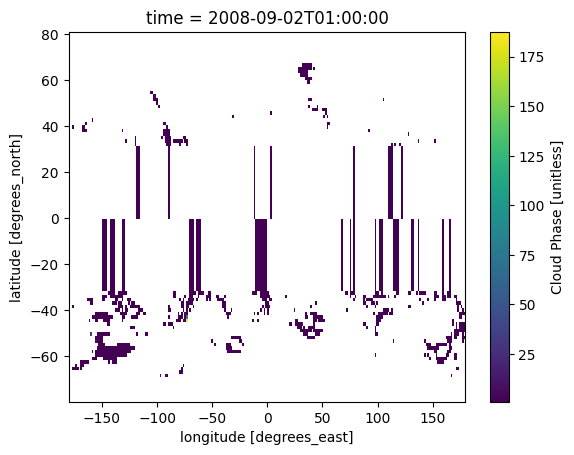

In [3]:
offline_3d_data_sample.isel(time=0)["cph_filtered"].plot()